In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [2]:
df = pd.read_csv('novagen_dataset.csv')

In [3]:
df.head()

,Age,BMI,Blood_Pressure,Cholesterol,Glucose_Level,Heart_Rate,Sleep_Hours,Exercise_Hours,Water_Intake,Stress_Level,...,Diet,MentalHealth,PhysicalActivity,MedicalHistory,Allergies,Diet_Type__Vegan,Diet_Type__Vegetarian,Blood_Group_AB,Blood_Group_B,Blood_Group_O
0,2.0,26.0,111.0,198.0,99.0,72.0,4.0,1.0,5.0,5.0,...,1,2,1,0,1,False,True,True,False,False
1,8.0,24.0,121.0,199.0,103.0,75.0,2.0,1.0,2.0,9.0,...,1,2,1,2,2,False,False,True,False,False
2,81.0,27.0,147.0,203.0,100.0,74.0,10.0,-0.0,5.0,1.0,...,2,0,0,1,0,True,False,False,False,False
3,25.0,21.0,150.0,199.0,102.0,70.0,7.0,3.0,3.0,3.0,...,1,2,1,2,0,True,False,False,True,False
4,24.0,26.0,146.0,202.0,99.0,76.0,10.0,2.0,5.0,1.0,...,2,0,2,0,2,False,True,False,True,False


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9549 entries, 0 to 9548
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Age                    9549 non-null   float64
 1   BMI                    9549 non-null   float64
 2   Blood_Pressure         9549 non-null   float64
 3   Cholesterol            9549 non-null   float64
 4   Glucose_Level          9549 non-null   float64
 5   Heart_Rate             9549 non-null   float64
 6   Sleep_Hours            9549 non-null   float64
 7   Exercise_Hours         9549 non-null   float64
 8   Water_Intake           9549 non-null   float64
 9   Stress_Level           9549 non-null   float64
 10  Target                 9549 non-null   int64  
 11  Smoking                9549 non-null   int64  
 12  Alcohol                9549 non-null   int64  
 13  Diet                   9549 non-null   int64  
 14  MentalHealth           9549 non-null   int64  
 15  Phys

([<matplotlib.patches.Wedge at 0x1fadf320830>,
 [Text(-0.07395202422684949, 1.097511320266334, 'healthy'),
  Text(0.0739519893407954, -1.0975113226170101, 'Unhealthy')],
 [Text(-0.04033746776009972, 0.5986425383270912, '52.1%'),
  Text(0.04033744873134294, -0.5986425396092782, '47.9%')])

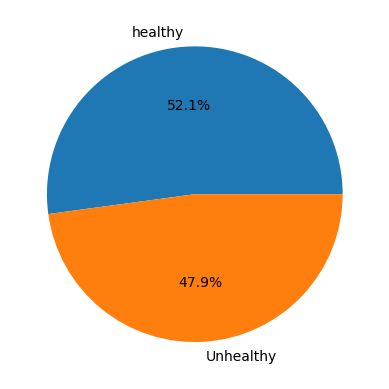

In [21]:
plt.pie(df['Target'].value_counts(), labels=['healthy', 'Unhealthy'], autopct='%1.1f%%')

<Axes: xlabel='Glucose_Level', ylabel='Blood_Pressure'>

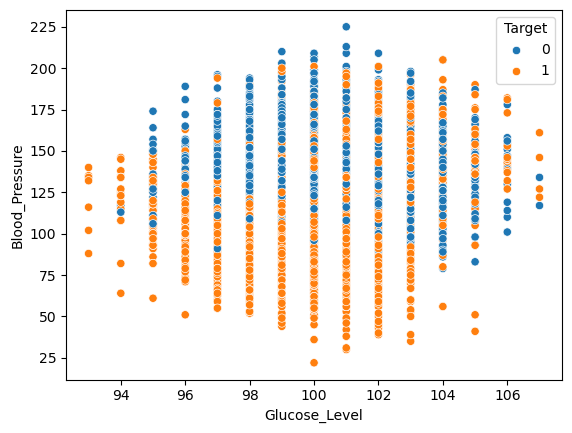

In [15]:
sns.scatterplot(df, x='Glucose_Level', y='Blood_Pressure', hue='Target')

<Axes: xlabel='BMI', ylabel='Stress_Level'>

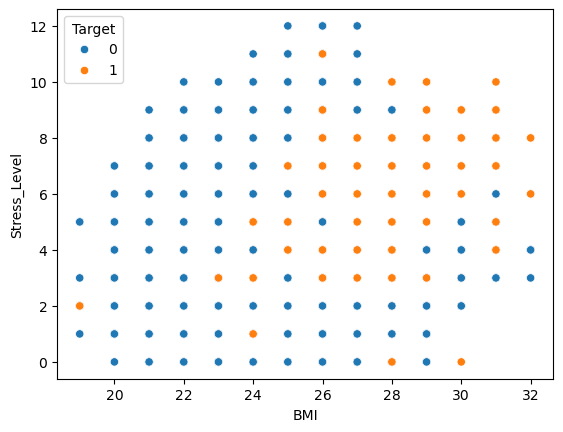

In [14]:
sns.scatterplot(df, x='BMI', y='Stress_Level', hue='Target')

<Axes: >

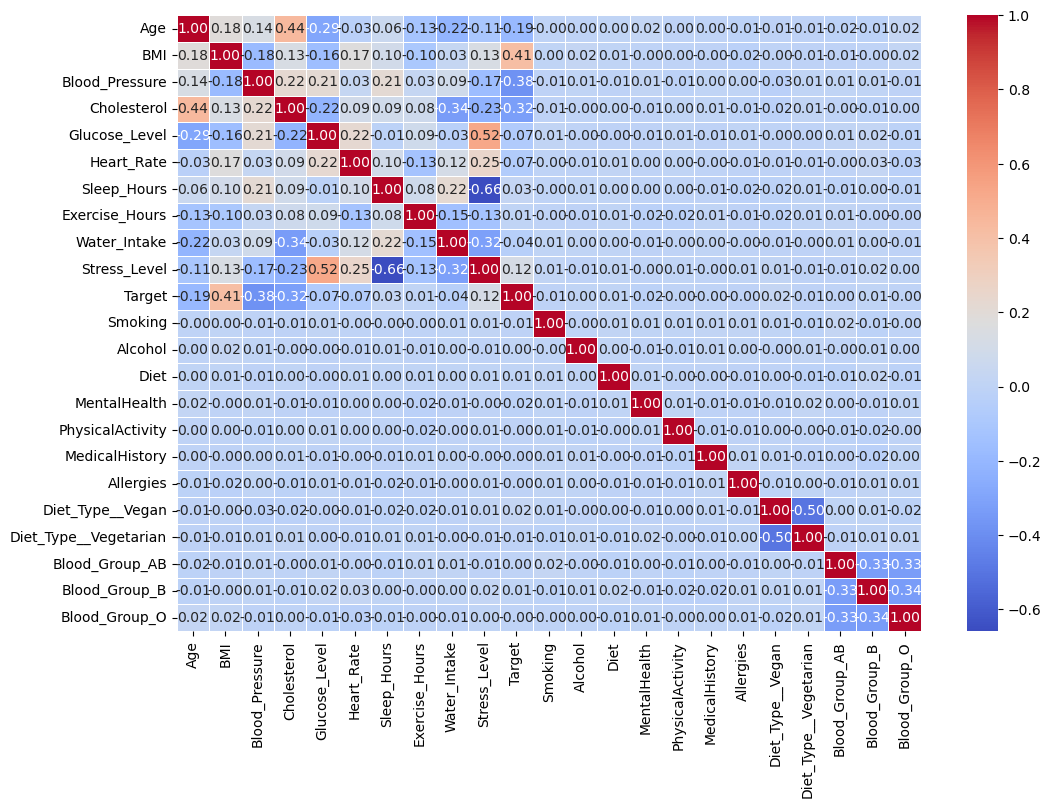

In [8]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

In [12]:
print(df.corr(numeric_only=True)['Target'].sort_values(ascending=False))

Target                   1.000000
BMI                      0.413972
Stress_Level             0.119455
Sleep_Hours              0.025931
Diet_Type__Vegan         0.023707
Exercise_Hours           0.008214
Blood_Group_B            0.007749
Diet                     0.005602
Alcohol                  0.003077
Blood_Group_AB           0.001174
MedicalHistory          -0.001666
PhysicalActivity        -0.002511
Blood_Group_O           -0.002728
Allergies               -0.004322
Diet_Type__Vegetarian   -0.005176
Smoking                 -0.005283
MentalHealth            -0.016372
Water_Intake            -0.038406
Heart_Rate              -0.065957
Glucose_Level           -0.072148
Age                     -0.190743
Cholesterol             -0.324361
Blood_Pressure          -0.380279
Name: Target, dtype: float64


In [22]:
df.isna().sum()

Age                      0
BMI                      0
Blood_Pressure           0
Cholesterol              0
Glucose_Level            0
Heart_Rate               0
Sleep_Hours              0
Exercise_Hours           0
Water_Intake             0
Stress_Level             0
Target                   0
Smoking                  0
Alcohol                  0
Diet                     0
MentalHealth             0
PhysicalActivity         0
MedicalHistory           0
Allergies                0
Diet_Type__Vegan         0
Diet_Type__Vegetarian    0
Blood_Group_AB           0
Blood_Group_B            0
Blood_Group_O            0
dtype: int64

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [40]:
X = df.drop('Target', axis=1)
y = df['Target']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state = 42
)


cat_cols = X_train.select_dtypes(include=['bool']).columns

num_cols = X_train.select_dtypes(include=['number']).columns


preprocessor = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

model = Pipeline([('preprocessor', preprocessor),
                  ('model', LogisticRegression(max_iter=5000, penalty='l1', solver='liblinear'))
])

model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [35]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, confusion_matrix, recall_score, classification_report

In [41]:
y_pred = model.predict(X_test)

print('cm ', confusion_matrix(y_test, y_pred))
print('accuracy_score ', accuracy_score(y_test, y_pred))
print('f1_score ', f1_score(y_test, y_pred))
print('precision_score ', precision_score(y_test, y_pred))
print('recall_score ', recall_score(y_test, y_pred))
print('cr ', classification_report(y_test, y_pred))

cm  [[722 178]
 [166 844]]
accuracy_score  0.8198952879581152
f1_score  0.8307086614173228
precision_score  0.8258317025440313
recall_score  0.8356435643564356
cr                precision    recall  f1-score   support

           0       0.81      0.80      0.81       900
           1       0.83      0.84      0.83      1010

    accuracy                           0.82      1910
   macro avg       0.82      0.82      0.82      1910
weighted avg       0.82      0.82      0.82      1910



In [43]:
from sklearn.model_selection import GridSearchCV

In [45]:
X = df.drop('Target', axis=1)
y = df['Target']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state = 42
)


cat_cols = X_train.select_dtypes(include=['bool']).columns

num_cols = X_train.select_dtypes(include=['number']).columns


preprocessor = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

model = Pipeline([('preprocessor', preprocessor),
                  ('model', DecisionTreeClassifier())
])

param_grid = {
    'model__max_depth':[4,5,6,7],
    'model__min_samples_split':[10,15,20,30],
    'model__min_samples_leaf':[10,15,20,30]
}

gridcv = GridSearchCV(
    model,
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
    
)

gridcv.fit(X_train, y_train)
y_pred = gridcv.predict(X_test)

print('cm ', confusion_matrix(y_test, y_pred))
print('accuracy_score ', accuracy_score(y_test, y_pred))
print('f1_score ', f1_score(y_test, y_pred))
print('precision_score ', precision_score(y_test, y_pred))
print('recall_score ', recall_score(y_test, y_pred))
print('cr ', classification_report(y_test, y_pred))

Fitting 3 folds for each of 64 candidates, totalling 192 fits
cm  [[757 143]
 [ 68 942]]
accuracy_score  0.8895287958115183
f1_score  0.8992840095465394
precision_score  0.8682027649769585
recall_score  0.9326732673267327
cr                precision    recall  f1-score   support

           0       0.92      0.84      0.88       900
           1       0.87      0.93      0.90      1010

    accuracy                           0.89      1910
   macro avg       0.89      0.89      0.89      1910
weighted avg       0.89      0.89      0.89      1910



In [46]:
print('Best Param ', gridcv.best_params_)
print('Best score ', gridcv.best_score_)
print('Best estimator ', gridcv.best_estimator_)

Best Param  {'model__max_depth': 7, 'model__min_samples_leaf': 10, 'model__min_samples_split': 15}
Best score  0.8818418198242918
Best estimator  Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  Index(['Age', 'BMI', 'Blood_Pressure', 'Cholesterol', 'Glucose_Level',
       'Heart_Rate', 'Sleep_Hours', 'Exercise_Hours', 'Water_Intake',
       'Stress_Level', 'Smoking', 'Alcohol', 'Diet', 'MentalHealth',
       'PhysicalActivity', 'MedicalHistory', 'Allergies'],
      dtype='object')),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  Index(['Diet_Type__Vegan', 'Diet_Type__Vegetarian', 'Blood_Group_AB',
       'Blood_Group_B', 'Blood_Group_O'],
      dtype='object'))])),
                ('model',
                 DecisionTreeClassifier(max_

In [50]:
X = df.drop('Target', axis=1)
y = df['Target']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state = 42
)


cat_cols = X_train.select_dtypes(include=['bool']).columns

num_cols = X_train.select_dtypes(include=['number']).columns


preprocessor = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

model = Pipeline([('preprocessor', preprocessor),
                  ('model', SVC())
])

param_grid = {
    'model__kernel':['rbf','poly','linear','sigmoid']
}

gridcv = GridSearchCV(
    model,
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
    
)

gridcv.fit(X_train, y_train)
y_pred = gridcv.predict(X_test)

print('cm ', confusion_matrix(y_test, y_pred))
print('accuracy_score ', accuracy_score(y_test, y_pred))
print('f1_score ', f1_score(y_test, y_pred))
print('precision_score ', precision_score(y_test, y_pred))
print('recall_score ', recall_score(y_test, y_pred))
print('cr ', classification_report(y_test, y_pred))

Fitting 3 folds for each of 4 candidates, totalling 12 fits
cm  [[705 195]
 [140 870]]
accuracy_score  0.824607329842932
f1_score  0.8385542168674699
precision_score  0.8169014084507042
recall_score  0.8613861386138614
cr                precision    recall  f1-score   support

           0       0.83      0.78      0.81       900
           1       0.82      0.86      0.84      1010

    accuracy                           0.82      1910
   macro avg       0.83      0.82      0.82      1910
weighted avg       0.83      0.82      0.82      1910



In [53]:
print('Best Param of SVC ', gridcv.best_params_)

Best Param of SVC  {'model__kernel': 'linear'}


In [54]:
X = df.drop('Target', axis=1)
y = df['Target']


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state = 42
)


cat_cols = X_train.select_dtypes(include=['bool']).columns

num_cols = X_train.select_dtypes(include=['number']).columns


preprocessor = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

model = Pipeline([('preprocessor', preprocessor),
                  ('model', RandomForestClassifier(oob_score=True))
])

param_grid = {
    'model__max_depth':[4,5,6,7],
    'model__min_samples_split':[10,15,20,30],
    'model__min_samples_leaf':[10,15,20,30],
    'model__n_estimators':[101, 151, 201]
}

gridcv = GridSearchCV(
    model,
    param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
    
)

gridcv.fit(X_train, y_train)
y_pred = gridcv.predict(X_test)

print('cm ', confusion_matrix(y_test, y_pred))
print('accuracy_score ', accuracy_score(y_test, y_pred))
print('f1_score ', f1_score(y_test, y_pred))
print('precision_score ', precision_score(y_test, y_pred))
print('recall_score ', recall_score(y_test, y_pred))
print('cr ', classification_report(y_test, y_pred))

Fitting 3 folds for each of 192 candidates, totalling 576 fits
cm  [[787 113]
 [ 73 937]]
accuracy_score  0.9026178010471204
f1_score  0.9097087378640777
precision_score  0.8923809523809524
recall_score  0.9277227722772278
cr                precision    recall  f1-score   support

           0       0.92      0.87      0.89       900
           1       0.89      0.93      0.91      1010

    accuracy                           0.90      1910
   macro avg       0.90      0.90      0.90      1910
weighted avg       0.90      0.90      0.90      1910



CLASSIFICATION MODEL PERFORMANCE


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,81.99%,82.58%,83.56%,83.07%
1,Decision Tree,88.95%,86.82%,93.27%,89.93%
2,SVC,82.46%,81.69%,86.14%,83.86%
3,Random Forest,90.26%,89.24%,92.77%,90.97%


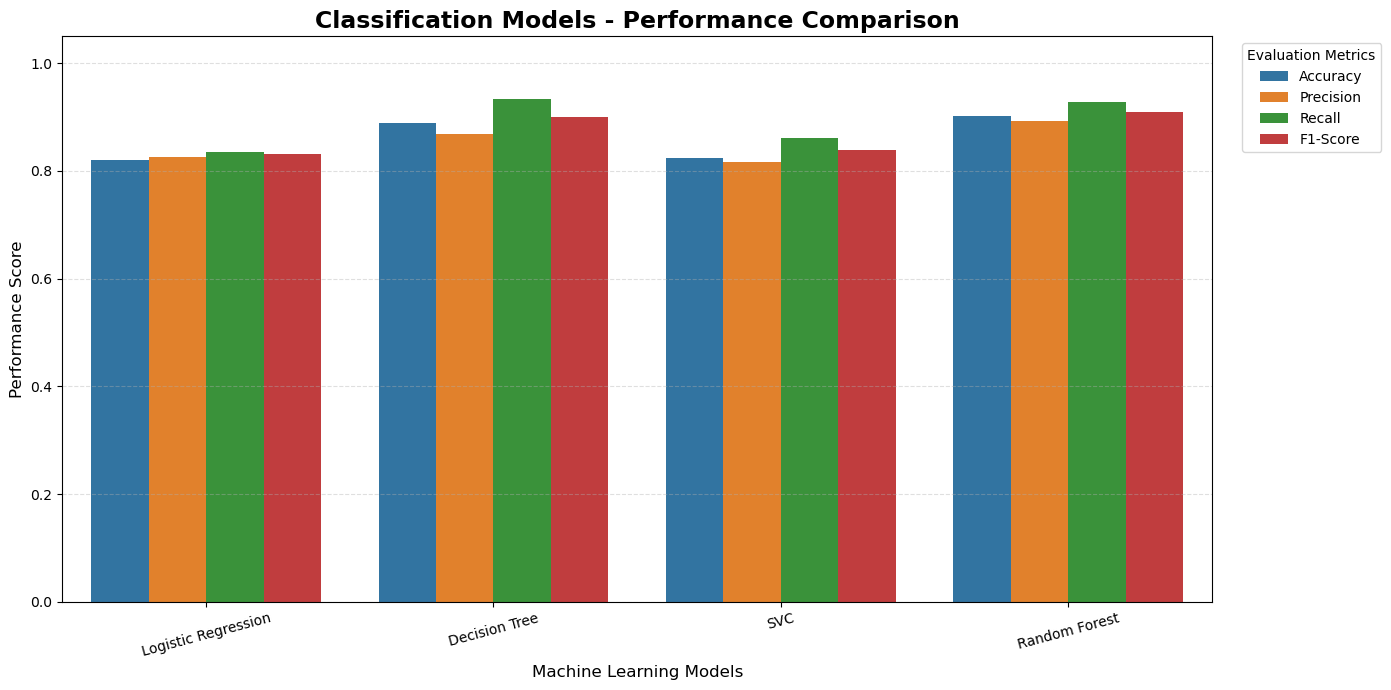

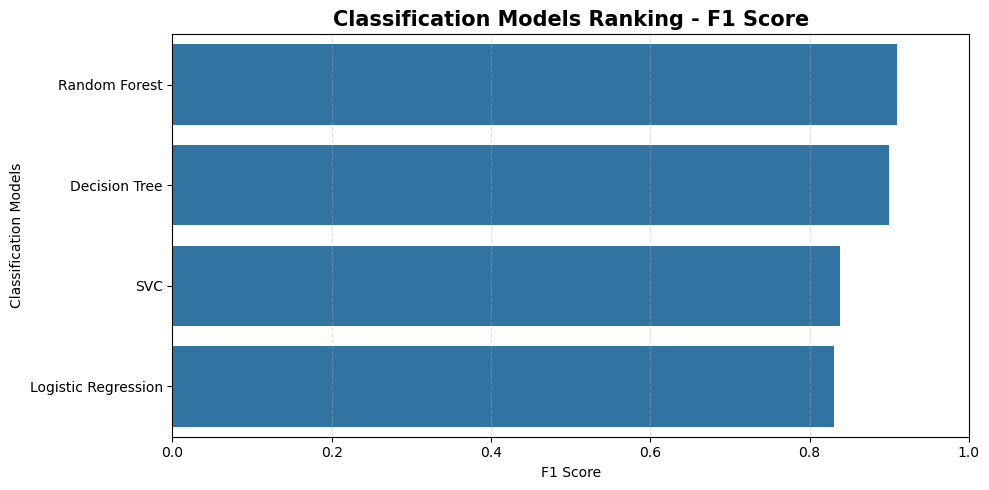


BEST PERFORMING MODEL
---------------------------
Model: Random Forest
Accuracy: 90.26%
Precision: 89.24%
Recall: 92.77%
F1-Score: 90.97%


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

performance = pd.DataFrame({

    'Model': [
        'Logistic Regression',
        'Decision Tree',
        'SVC',
        'Random Forest'
    ],

    'Accuracy': [
        0.8199,
        0.8895,
        0.8246,
        0.9026
    ],

    'Precision': [
        0.8258,
        0.8682,
        0.8169,
        0.8924
    ],

    'Recall': [
        0.8356,
        0.9327,
        0.8614,
        0.9277
    ],

    'F1-Score': [
        0.8307,
        0.8993,
        0.8386,
        0.9097
    ]
})


# =====================================
# 2. DISPLAY COMPARISON TABLE
# =====================================

print("CLASSIFICATION MODEL PERFORMANCE")

display(
    performance.style
    .format({
        'Accuracy': '{:.2%}',
        'Precision': '{:.2%}',
        'Recall': '{:.2%}',
        'F1-Score': '{:.2%}'
    })
    .highlight_max(
        subset=['Accuracy', 'Precision', 'Recall', 'F1-Score'],
        color='lightgreen'
    )
)


# =====================================
# 3. COMBINED PERFORMANCE VISUALIZATION
# =====================================

performance_melted = performance.melt(
    id_vars='Model',
    var_name='Metrics',
    value_name='Score'
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=performance_melted,
    x='Model',
    y='Score',
    hue='Metrics'
)

plt.title(
    'Classification Models - Performance Comparison',
    fontsize=17,
    fontweight='bold'
)

plt.xlabel('Machine Learning Models', fontsize=12)
plt.ylabel('Performance Score', fontsize=12)

plt.ylim(0, 1.05)

plt.xticks(rotation=15)

plt.legend(
    title='Evaluation Metrics',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


# =====================================
# 4. MODEL RANKING BASED ON F1 SCORE
# =====================================

ranking = performance.sort_values(
    by='F1-Score',
    ascending=False
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=ranking,
    x='F1-Score',
    y='Model'
)

plt.title(
    'Classification Models Ranking - F1 Score',
    fontsize=15,
    fontweight='bold'
)

plt.xlabel('F1 Score')
plt.ylabel('Classification Models')

plt.xlim(0, 1)

plt.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


# =====================================
# 5. BEST MODEL
# =====================================

best_model = ranking.iloc[0]

print("\nBEST PERFORMING MODEL")
print("---------------------------")

print("Model:", best_model['Model'])
print("Accuracy:", f"{best_model['Accuracy']:.2%}")
print("Precision:", f"{best_model['Precision']:.2%}")
print("Recall:", f"{best_model['Recall']:.2%}")
print("F1-Score:", f"{best_model['F1-Score']:.2%}")